# Trabajo Práctico 2 · Algoritmos de predicción y evaluación de modelos
**Aprendizaje Automático y Grandes Datos · UNRaf · 2026**
**Integrantes:** Gino Ficetto y Bautista Ferrer

**Pregunta de predicción.** ¿Se puede estimar la DEP de peso a los 18 meses de un toro (en kg) a partir de los caracteres que se conocen antes: las DEP de peso al nacer, peso al destete, aptitud materna y circunferencia escrotal, y su año de nacimiento?

| | |
|---|---|
| **Datos** | Sumarios de padres 2026 de la Asociación Braford Argentina y de la Asociación Argentina de Brangus: 2329 toros (1106 Braford y 1223 Brangus), la base del TP1 con la tabla Braford completa. |
| **Objetivo (target)** | `Peso18Meses_DEP`: diferencia esperada, en kg, entre el peso a los 18 meses de los hijos del toro y el promedio de su raza. Es variable continua. |
| **Algoritmos** | Regresión lineal múltiple (línea base), k vecinos más cercanos y Random Forest: un modelo lineal, uno basado en instancias y un ensamble de árboles. |
| **Raza** | Braford es el análisis principal; la sección 6 replica todo en Brangus. |
| **Reproducibilidad** | Semilla 2026 en la partición, la validación cruzada y los modelos. Ejecutar las celdas en orden. Las figuras se guardan en `figuras/` y los números en `resultados_tp2.json`. |

## 0 · Preparación del entorno

In [1]:
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats

from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_validate, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, mean_absolute_percentage_error
from sklearn.inspection import permutation_importance

SEMILLA = 2026
RAZA = "Braford"                 # raza principal; la sección 6 replica todo en Brangus
OBJETIVO = "Peso18Meses_DEP"
PREDICTORAS = ["PesoNacer_DEP", "PesoDestete_DEP", "AptitudMaterna_DEP", "CircEscrotal_DEP", "Anio_Nacimiento"]
NOMBRES = {"PesoNacer_DEP": "DEP nacer", "PesoDestete_DEP": "DEP destete", "AptitudMaterna_DEP": "DEP aptitud materna",
           "CircEscrotal_DEP": "DEP circ. escrotal", "Anio_Nacimiento": "Año de nacimiento"}
AZUL, AMBAR, GRIS, ROJO, VERDE = "#0055a5", "#f0a800", "#6b7280", "#c0392b", "#2e8b57"
COLOR_MODELO = {"Regresión lineal": AZUL, "k vecinos": AMBAR, "Random Forest": VERDE}
FIG = Path("figuras"); FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 140)

toros = pd.read_csv("datos/toros_braford_brangus.csv")
print(f"Base completa: {len(toros)} toros ({(toros.Raza == 'Braford').sum()} Braford, {(toros.Raza == 'Brangus').sum()} Brangus)")

Base completa: 2329 toros (1106 Braford, 1223 Brangus)


## A · Marco experimental

### A.1 · El problema y su relevancia
En el TP1 la pregunta fue cuál es el toro de cada raza con más kilos a los 18 meses, medido por la DEP de peso a los 18 meses. Ese dato tiene una limitación práctica: la DEP de 18 meses de un toro joven tiene poca precisión, porque se apoya en pocos hijos pesados a esa edad. Las DEP de nacimiento y destete, y la de circunferencia escrotal, se conocen antes y con más datos. **Si se pudiera estimar la DEP de 18 meses a partir de ellas, un productor podría anticipar qué toros jóvenes prometen más kilos a los 18 meses**, que es lo que define si una vaquillona llega al entore y si un novillo sale terminado.

### A.2 · Variables predictoras: inclusiones y exclusiones
- **Incluidas:** las DEP de peso al nacer, peso al destete, aptitud materna y circunferencia escrotal (los caracteres tempranos del sumario) y el año de nacimiento (la tendencia genética: los toros más nuevos tienden a tener DEP más altas).
- **Excluidas:**
  - *Leche y Crecimiento:* la celda siguiente muestra que es exactamente aptitud materna + ½ destete. Sumarla duplicaría información y haría que la regresión lineal tenga una columna que es combinación exacta de otras dos (multicolinealidad perfecta).
  - *Las precisiones y los RANK:* la precisión mide la confiabilidad de cada DEP, no el carácter; el RANK de 18 meses sale del objetivo y sería fuga de información.
  - *Crías y rodeos:* describen cuánto se usó el toro, no su genética.
  - *Nombre, apodo, HBA:* identificadores.
- **Cada raza por separado:** como se estableció en el TP1, las DEP se miden contra la base de cada raza y no se comparan entre razas.

In [2]:
# Leche y Crecimiento: ¿es una combinación exacta de otras dos columnas?
lc_calc = toros["AptitudMaterna_DEP"] + 0.5 * toros["PesoDestete_DEP"]
dif = (toros["LecheYCrecimiento_DEP"] - lc_calc).abs()
print(f"Leche y Crecimiento − (Aptitud materna + ½ Destete): diferencia máxima = {dif.max():.3f} kg (redondeo del sumario)")
print(f"Correlación entre las dos: {np.corrcoef(toros['LecheYCrecimiento_DEP'], lc_calc)[0, 1]:.4f}")

Leche y Crecimiento − (Aptitud materna + ½ Destete): diferencia máxima = 0.010 kg (redondeo del sumario)
Correlación entre las dos: 1.0000


In [3]:
datos = toros[toros["Raza"] == RAZA].reset_index(drop=True)
print(f"{RAZA}: {len(datos)} toros")
print("Faltantes en predictoras y objetivo:")
print(datos[PREDICTORAS + [OBJETIVO]].isna().sum().to_string())
datos[PREDICTORAS + [OBJETIVO]].describe().round(2)

Braford: 1106 toros
Faltantes en predictoras y objetivo:
PesoNacer_DEP         0
PesoDestete_DEP       0
AptitudMaterna_DEP    0
CircEscrotal_DEP      0
Anio_Nacimiento       1
Peso18Meses_DEP       0


,PesoNacer_DEP,PesoDestete_DEP,AptitudMaterna_DEP,CircEscrotal_DEP,Anio_Nacimiento,Peso18Meses_DEP
count,1106.00,1106.00,1106.00,1106.00,1105.00,1106.00
mean,0.37,6.82,0.82,0.67,2014.24,17.92
std,0.74,5.45,3.19,0.44,5.34,13.08
min,-3.38,-13.55,-9.21,-0.73,1986.00,-18.99
25%,-0.07,3.43,-1.22,0.38,2011.00,9.52
50%,0.34,6.92,0.68,0.66,2015.00,16.21
75%,0.82,10.37,2.84,0.94,2018.00,25.08
max,3.01,28.38,13.35,3.12,2023.00,87.24


Hay un solo faltante en las predictoras de Braford (el año de nacimiento de un toro). Se imputa con la mediana **adentro del flujo**, para que el valor se aprenda solo con el entrenamiento.

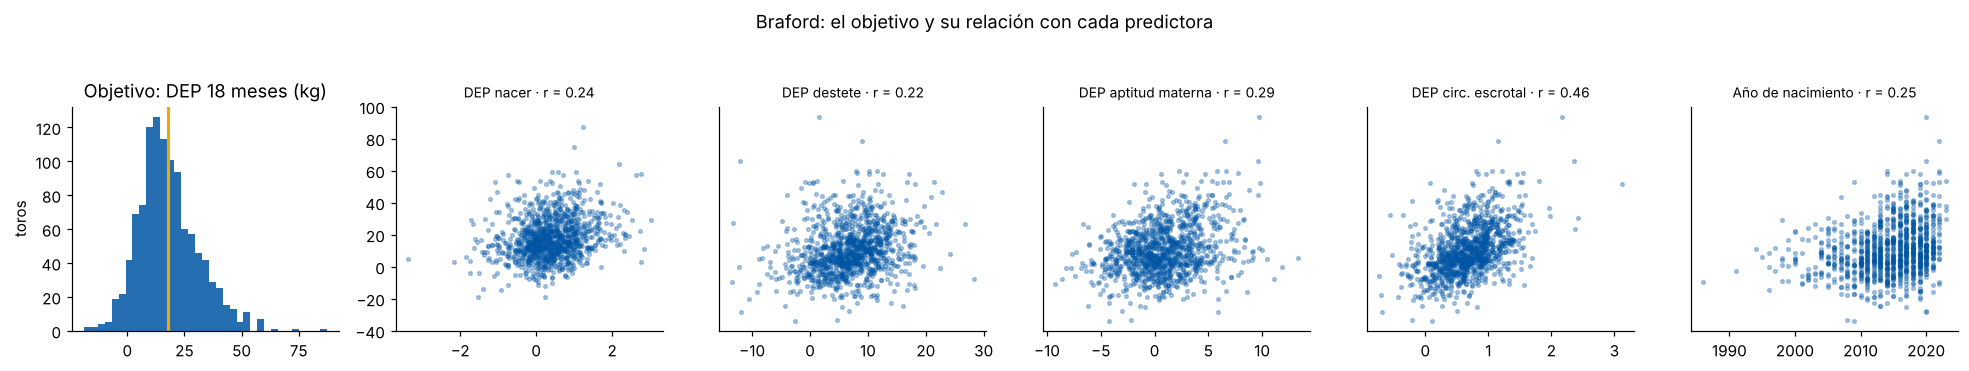

Correlación entre predictoras:
                     DEP nacer  DEP destete  DEP aptitud materna  DEP circ. escrotal  Año de nacimiento
DEP nacer                 1.00         0.24                -0.04                0.15              -0.04
DEP destete               0.24         1.00                -0.52                0.19              -0.01
DEP aptitud materna      -0.04        -0.52                 1.00                0.06               0.12
DEP circ. escrotal        0.15         0.19                 0.06                1.00               0.26
Año de nacimiento        -0.04        -0.01                 0.12                0.26               1.00


In [4]:
fig, ejes = plt.subplots(1, 6, figsize=(18, 3.2))
ejes[0].hist(datos[OBJETIVO], bins=35, color=AZUL, alpha=0.85)
ejes[0].axvline(datos[OBJETIVO].mean(), color=AMBAR, lw=2)
ejes[0].set_title("Objetivo: DEP 18 meses (kg)"); ejes[0].set_ylabel("toros")
for ax, col in zip(ejes[1:], PREDICTORAS):
    ax.scatter(datos[col], datos[OBJETIVO], s=6, alpha=0.3, color=AZUL)
    r = datos[[col, OBJETIVO]].corr().iloc[0, 1]
    ax.set_title(f"{NOMBRES[col]} · r = {r:.2f}", fontsize=9); ax.set_yticks([] if col != PREDICTORAS[0] else ax.get_yticks())
fig.suptitle(f"{RAZA}: el objetivo y su relación con cada predictora", y=1.04)
plt.tight_layout(); fig.savefig(FIG / f"tp2_eda_{RAZA}.png", bbox_inches="tight"); plt.show()
print("Correlación entre predictoras:")
print(datos[PREDICTORAS].corr().round(2).rename(index=NOMBRES, columns=NOMBRES).to_string())

**Qué se ve.** El objetivo es aproximadamente simétrico, con una cola a la derecha (unos pocos toros con DEP muy altas, como el de 87 kg del TP1). Ninguna predictora explica mucho sola: la correlación más alta es la de circunferencia escrotal (0,46). En Braford el destete se relaciona poco con los 18 meses (0,22), algo que ya había aparecido en el TP1. Entre predictoras, la única correlación fuerte es destete con aptitud materna (−0,52).

### A.3 · Partición de los datos
- **Hold-out 80/20** con semilla 2026: 884 toros para entrenar y 222 para probar. La prueba se usa una sola vez por modelo, al final.
- **Validación cruzada de 5 pliegues** (`KFold`, semilla 2026) sobre el entrenamiento, para elegir hiperparámetros y para estimar el error con su dispersión. Con 1106 toros, una sola partición puede ser optimista o pesimista por azar; la validación cruzada da la media y el desvío.
- Todo el preprocesamiento (imputar y escalar) está adentro de un `Pipeline`, así nada de la prueba se filtra al entrenamiento.

In [5]:
X = datos[PREDICTORAS]
y = datos[OBJETIVO]
X_ent, X_pru, y_ent, y_pru = train_test_split(X, y, test_size=0.2, random_state=SEMILLA)
pliegues = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)
print(f"Entrenamiento: {len(X_ent)} toros · prueba: {len(X_pru)} toros · semilla {SEMILLA}")
print(f"Media del objetivo: entrenamiento {y_ent.mean():.2f} kg · prueba {y_pru.mean():.2f} kg")

Entrenamiento: 884 toros · prueba: 222 toros · semilla 2026
Media del objetivo: entrenamiento 17.87 kg · prueba 18.13 kg


### A.4 · Métricas y línea base
Métricas obligatorias: **MSE, RMSE, MAE y R²**; complementarias: **R² ajustado** y **MAPE**. Todas se calculan en entrenamiento y en prueba, para diagnosticar sobreajuste.

La **línea base** de la consigna es la regresión lineal múltiple (sección B.1). Antes se registra una referencia todavía más simple, predecir siempre la media del entrenamiento: cualquier modelo útil tiene que bajar de ese error.

In [6]:
def metricas(y_real, y_pred, p=len(PREDICTORAS)):
    n = len(y_real); r2 = r2_score(y_real, y_pred); mse = mean_squared_error(y_real, y_pred)
    return {"MSE": mse, "RMSE": np.sqrt(mse), "MAE": mean_absolute_error(y_real, y_pred), "R²": r2,
            "R² ajustado": 1 - (1 - r2) * (n - 1) / (n - p - 1), "MAPE (%)": 100 * mean_absolute_percentage_error(y_real, y_pred)}

resultados = {}
def registrar(nombre, modelo, ajustar=True):
    if ajustar:
        t0 = time.perf_counter(); modelo.fit(X_ent, y_ent); t = time.perf_counter() - t0
    else:
        t = np.nan
    cv = cross_validate(modelo, X_ent, y_ent, cv=pliegues, scoring=("neg_root_mean_squared_error", "r2"))
    resultados[nombre] = {"modelo": modelo, "entrenamiento": metricas(y_ent, modelo.predict(X_ent)),
                          "prueba": metricas(y_pru, modelo.predict(X_pru)),
                          "RMSE CV": (-cv["test_neg_root_mean_squared_error"].mean(), cv["test_neg_root_mean_squared_error"].std()),
                          "R² CV": (cv["test_r2"].mean(), cv["test_r2"].std()), "ajuste (s)": t}
    e, p = resultados[nombre]["entrenamiento"], resultados[nombre]["prueba"]
    print(f"{nombre}: RMSE entrenamiento {e['RMSE']:.2f} · prueba {p['RMSE']:.2f} | R² entrenamiento {e['R²']:.3f} · prueba {p['R²']:.3f} | "
          f"R² CV {resultados[nombre]['R² CV'][0]:.3f} ± {resultados[nombre]['R² CV'][1]:.3f}")
    return modelo

def flujo(modelo, escalar=True):
    pasos = [("imputar", SimpleImputer(strategy="median"))]
    if escalar: pasos.append(("escalar", StandardScaler()))
    return Pipeline(pasos + [("modelo", modelo)])

registrar("Referencia: predecir la media", flujo(DummyRegressor(strategy="mean"), escalar=False));

Referencia: predecir la media: RMSE entrenamiento 13.08 · prueba 13.06 | R² entrenamiento 0.000 · prueba -0.000 | R² CV -0.006 ± 0.006


## B · Implementación y entrenamiento

### B.1 · Regresión lineal múltiple (línea base)
**Hiperparámetros:** los de la biblioteca (`fit_intercept=True`). No tiene hiperparámetros que ajustar; las predictoras se escalan (`StandardScaler`) para que los coeficientes se puedan comparar entre sí.

In [7]:
lineal = registrar("Regresión lineal", flujo(LinearRegression()))
coef = pd.Series(lineal["modelo"].coef_, index=[NOMBRES[c] for c in PREDICTORAS])
print(f"\nintercept_ = {lineal['modelo'].intercept_:.2f} kg (DEP 18 meses del toro promedio)")
print("coef_ (kg de DEP 18 meses por cada desvío estándar de la predictora):")
print(coef.round(2).to_string())

Regresión lineal: RMSE entrenamiento 10.01 · prueba 10.29 | R² entrenamiento 0.415 · prueba 0.379 | R² CV 0.402 ± 0.030

intercept_ = 17.87 kg (DEP 18 meses del toro promedio)
coef_ (kg de DEP 18 meses por cada desvío estándar de la predictora):
DEP nacer              1.54
DEP destete            5.01
DEP aptitud materna    6.15
DEP circ. escrotal     3.80
Año de nacimiento      1.72


**Lectura y ajuste.** Con las columnas escaladas, cada coeficiente es cuántos kg de DEP de 18 meses suma un desvío estándar de esa predictora. Todos son positivos; pesan más la aptitud materna (6,2 kg) y el destete (5,0 kg). El R² es 0,415 en entrenamiento y 0,379 en prueba: **casi no hay brecha, así que no sobreajusta**. El error es alto para los dos conjuntos por igual: es el patrón del **sesgo** (subajuste relativo), un modelo que no puede capturar más con estas variables.

### B.2 · k vecinos más cercanos
**Por qué:** no supone ninguna forma para la relación; predice el promedio de los k toros con DEP tempranas más parecidas. Si la relación no fuera lineal, debería ganarle a la recta.

**Hiperparámetros:** `n_neighbors` se elige con `GridSearchCV` (validación cruzada de 5 pliegues, RMSE) entre 3 y 100. Se usa `weights="uniform"`: con `"distance"` cada toro de entrenamiento es su propio vecino a distancia cero y el error de entrenamiento queda en cero por construcción, lo que impide diagnosticar el sobreajuste. El escalado es obligatorio: sin él la distancia la decidiría la columna de mayor rango (el año).

Mejor combinación: {'modelo__n_neighbors': 20, 'modelo__weights': 'uniform'} · RMSE CV = 10.48


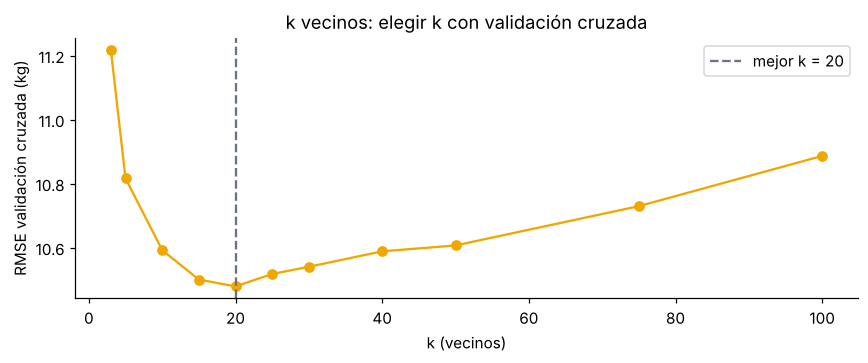

k vecinos (k = 5, por defecto): RMSE entrenamiento 8.81 · prueba 11.02 | R² entrenamiento 0.547 · prueba 0.287 | R² CV 0.312 ± 0.046
k vecinos: RMSE entrenamiento 9.92 · prueba 10.49 | R² entrenamiento 0.425 · prueba 0.354 | R² CV 0.355 ± 0.022


In [8]:
grilla_knn = {"modelo__n_neighbors": [3, 5, 10, 15, 20, 25, 30, 40, 50, 75, 100], "modelo__weights": ["uniform"]}
busq_knn = GridSearchCV(flujo(KNeighborsRegressor()), grilla_knn, cv=pliegues, scoring="neg_root_mean_squared_error").fit(X_ent, y_ent)
print("Mejor combinación:", busq_knn.best_params_, f"· RMSE CV = {-busq_knn.best_score_:.2f}")
tabla_k = pd.DataFrame(busq_knn.cv_results_)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(tabla_k["param_modelo__n_neighbors"], -tabla_k["mean_test_score"], marker="o", color=AMBAR)
ax.axvline(busq_knn.best_params_["modelo__n_neighbors"], color=GRIS, ls="--", label=f"mejor k = {busq_knn.best_params_['modelo__n_neighbors']}")
ax.set_xlabel("k (vecinos)"); ax.set_ylabel("RMSE validación cruzada (kg)"); ax.legend()
ax.set_title("k vecinos: elegir k con validación cruzada")
plt.tight_layout(); fig.savefig(FIG / f"tp2_knn_k_{RAZA}.png", bbox_inches="tight"); plt.show()
registrar("k vecinos (k = 5, por defecto)", flujo(KNeighborsRegressor()))
knn = registrar("k vecinos", busq_knn.best_estimator_, ajustar=False)

**Lectura y ajuste.** Con k = 5 (el valor por defecto) el modelo sobreajusta: R² 0,547 en entrenamiento y 0,287 en prueba. Con k = 20 la brecha se achica (0,425 contra 0,354) y el error de validación cruzada baja. Subir k aumenta el sesgo y baja la varianza.

### B.3 · Random Forest (ensamble de árboles)
**Por qué:** 300 árboles de decisión entrenados sobre muestras con reposición y promediados. Captura no linealidades e interacciones sin especificarlas, y su promedio reduce la varianza de un árbol solo. Es además el método de ensamble del trabajo.

**Hiperparámetros:** `n_estimators=300` fijo (más árboles no sobreajustan, solo cuestan tiempo). Con `GridSearchCV` se eligen `max_depth` (sin límite, 4, 6, 8, 12), `min_samples_leaf` (1, 5, 10, 20) y `max_features` (raíz cuadrada o todas): 40 combinaciones por 5 pliegues. No necesita escalar.

In [9]:
registrar("Random Forest (por defecto)", flujo(RandomForestRegressor(n_estimators=300, random_state=SEMILLA, n_jobs=-1), escalar=False))
grilla_rf = {"modelo__max_depth": [None, 4, 6, 8, 12], "modelo__min_samples_leaf": [1, 5, 10, 20], "modelo__max_features": ["sqrt", 1.0]}
busq_rf = GridSearchCV(flujo(RandomForestRegressor(n_estimators=300, random_state=SEMILLA, n_jobs=-1), escalar=False),
                       grilla_rf, cv=pliegues, scoring="neg_root_mean_squared_error", n_jobs=-1).fit(X_ent, y_ent)
print("Mejor combinación:", busq_rf.best_params_, f"· RMSE CV = {-busq_rf.best_score_:.2f}")
rf = registrar("Random Forest", busq_rf.best_estimator_, ajustar=False)

Random Forest (por defecto): RMSE entrenamiento 3.84 · prueba 10.64 | R² entrenamiento 0.914 · prueba 0.336 | R² CV 0.352 ± 0.050


Mejor combinación: {'modelo__max_depth': 8, 'modelo__max_features': 1.0, 'modelo__min_samples_leaf': 5} · RMSE CV = 10.33


Random Forest: RMSE entrenamiento 7.58 · prueba 10.58 | R² entrenamiento 0.664 · prueba 0.343 | R² CV 0.370 ± 0.060


**Lectura y ajuste.** Con los valores por defecto el bosque **sobreajusta fuerte**: R² 0,914 en entrenamiento y 0,336 en prueba; memoriza a los toros de entrenamiento. Limitando la profundidad a 8 y pidiendo al menos 5 toros por hoja, la brecha baja (0,664 contra 0,343) y mejora la validación cruzada, pero sigue siendo el modelo con más varianza de los tres.

## C · Evaluación y comparación

### C.1 · Tabla comparativa: entrenamiento y prueba

In [10]:
filas = []
for nombre, r in resultados.items():
    for parte in ["entrenamiento", "prueba"]:
        filas.append({"Modelo": nombre, "Conjunto": parte, **r[parte]})
tabla = pd.DataFrame(filas).set_index(["Modelo", "Conjunto"])
cv_tabla = pd.DataFrame({n: {"RMSE CV (media ± desvío)": f"{r['RMSE CV'][0]:.2f} ± {r['RMSE CV'][1]:.2f}",
                             "R² CV (media ± desvío)": f"{r['R² CV'][0]:.3f} ± {r['R² CV'][1]:.3f}"} for n, r in resultados.items()}).T
display(tabla.style.format({"MSE": "{:.1f}", "RMSE": "{:.2f}", "MAE": "{:.2f}", "R²": "{:.3f}", "R² ajustado": "{:.3f}", "MAPE (%)": "{:.0f}"}))
cv_tabla

,RMSE CV (media ± desvío),R² CV (media ± desvío)
Referencia: predecir la media,13.09 ± 0.44,-0.006 ± 0.006
Regresión lineal,10.08 ± 0.30,0.402 ± 0.030
"k vecinos (k = 5, por defecto)",10.82 ± 0.48,0.312 ± 0.046
k vecinos,10.48 ± 0.35,0.355 ± 0.022
Random Forest (por defecto),10.49 ± 0.32,0.352 ± 0.050
Random Forest,10.33 ± 0.38,0.370 ± 0.060


**Por qué el MAPE no sirve en este problema.** El MAPE divide el error por el valor real, y hay DEP de 18 meses cercanas a cero (y negativas). La celda siguiente lo muestra: en los toros con DEP menor a 2 kg en valor absoluto, un error de pocos kg se vuelve un error de más de mil por ciento. Se reporta porque la consigna lo valora, pero **no se usa para elegir**: el RMSE y el MAE, en kg, son las métricas interpretables.

In [11]:
ape = (np.abs(y_pru - lineal.predict(X_pru)) / np.abs(y_pru)) * 100
print(f"Toros de prueba con |DEP 18 meses| < 2 kg: {(y_pru.abs() < 2).sum()} · su error porcentual medio: {ape[y_pru.abs() < 2].mean():.0f} %")
print(f"Resto de los toros: error porcentual medio {ape[y_pru.abs() >= 2].mean():.0f} %")

Toros de prueba con |DEP 18 meses| < 2 kg: 11 · su error porcentual medio: 1775 %
Resto de los toros: error porcentual medio 64 %


### C.2 · Visualizaciones comparativas

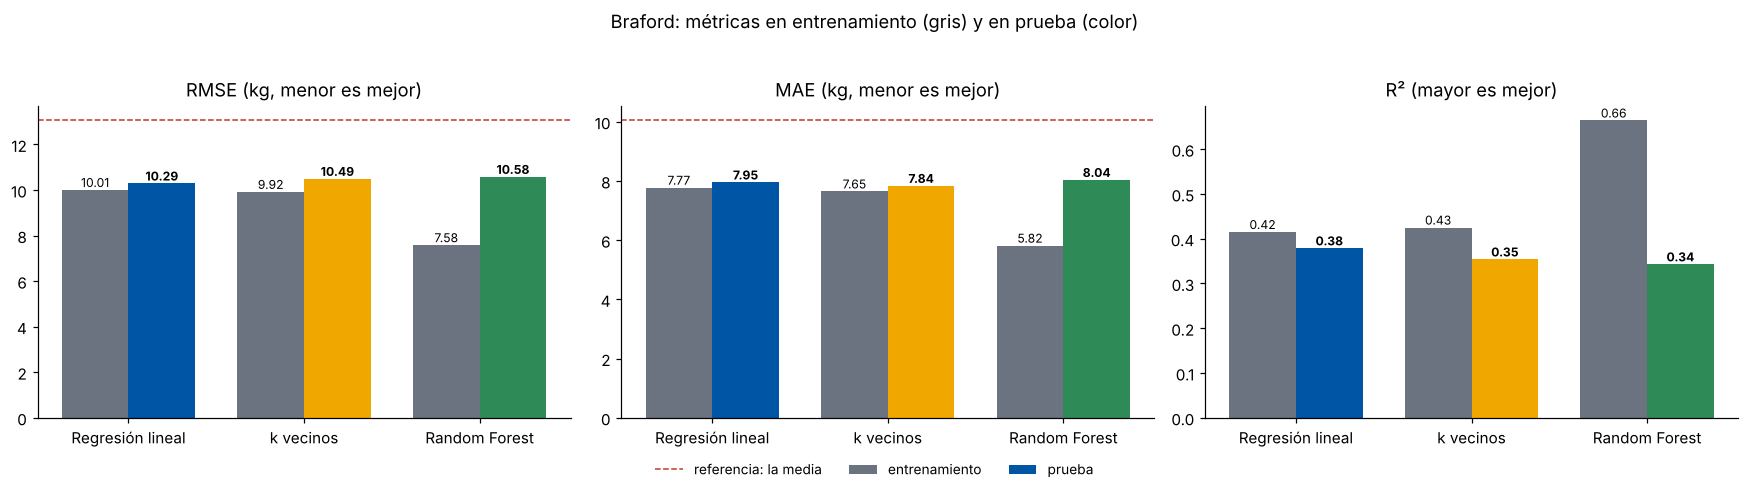

In [12]:
FINALES = ["Regresión lineal", "k vecinos", "Random Forest"]
fig, ejes = plt.subplots(1, 3, figsize=(16, 4))
for ax, m in zip(ejes, ["RMSE", "MAE", "R²"]):
    x = np.arange(len(FINALES)); w = 0.38
    ent = [resultados[n]["entrenamiento"][m] for n in FINALES]; pru = [resultados[n]["prueba"][m] for n in FINALES]
    ax.bar(x - w / 2, ent, w, color=GRIS, label="entrenamiento"); ax.bar(x + w / 2, pru, w, color=[COLOR_MODELO[n] for n in FINALES], label="prueba")
    for i, (a, b) in enumerate(zip(ent, pru)):
        ax.text(i - w / 2, a, f"{a:.2f}", ha="center", va="bottom", fontsize=8); ax.text(i + w / 2, b, f"{b:.2f}", ha="center", va="bottom", fontsize=8, fontweight="bold")
    ax.set_xticks(x); ax.set_xticklabels(FINALES); ax.set_title(m + (" (kg, menor es mejor)" if m != "R²" else " (mayor es mejor)"))
    if m != "R²": ax.axhline(resultados["Referencia: predecir la media"]["prueba"][m], color=ROJO, ls="--", lw=1, label="referencia: la media")
h, l = ejes[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=3, fontsize=9, frameon=False, bbox_to_anchor=(0.5, -0.06))
fig.suptitle(f"{RAZA}: métricas en entrenamiento (gris) y en prueba (color)", y=1.03)
plt.tight_layout(); fig.savefig(FIG / f"tp2_metricas_{RAZA}.png", bbox_inches="tight"); plt.show()

**Qué se ve.** En las barras, la regresión lineal es la única con entrenamiento y prueba casi iguales; los otros dos aprenden más el entrenamiento de lo que generalizan. Los tres bajan claramente de la referencia (la línea roja, predecir la media).

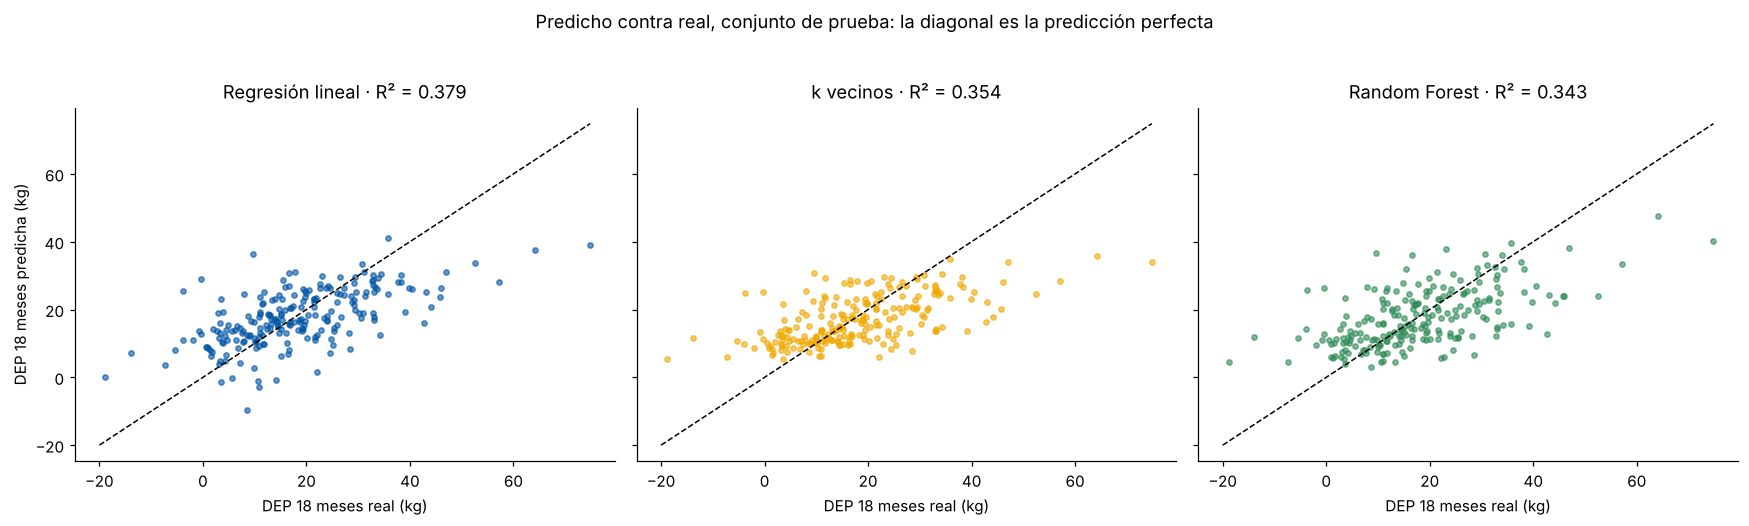

In [13]:
fig, ejes = plt.subplots(1, 3, figsize=(16, 4.6), sharex=True, sharey=True)
lim = [min(y_pru.min(), -20), max(y_pru.max(), 70)]
for ax, n in zip(ejes, FINALES):
    pred = resultados[n]["modelo"].predict(X_pru)
    ax.scatter(y_pru, pred, s=12, alpha=0.6, color=COLOR_MODELO[n]); ax.plot(lim, lim, color="black", lw=1, ls="--")
    ax.set_title(f"{n} · R² = {resultados[n]['prueba']['R²']:.3f}"); ax.set_xlabel("DEP 18 meses real (kg)")
ejes[0].set_ylabel("DEP 18 meses predicha (kg)")
fig.suptitle("Predicho contra real, conjunto de prueba: la diagonal es la predicción perfecta", y=1.03)
plt.tight_layout(); fig.savefig(FIG / f"tp2_pred_real_{RAZA}.png", bbox_inches="tight"); plt.show()

**Qué se ve.** Los tres modelos tienen el mismo defecto: la nube de predicho contra real es más horizontal que la diagonal. **A los toros de DEP muy alta les predicen de menos y a los de DEP muy baja, de más** (regresión hacia la media). Las predicciones se mueven en un rango mucho más angosto que los valores reales: con un R² cercano a 0,38, ningún modelo reconoce bien a los toros extremos.

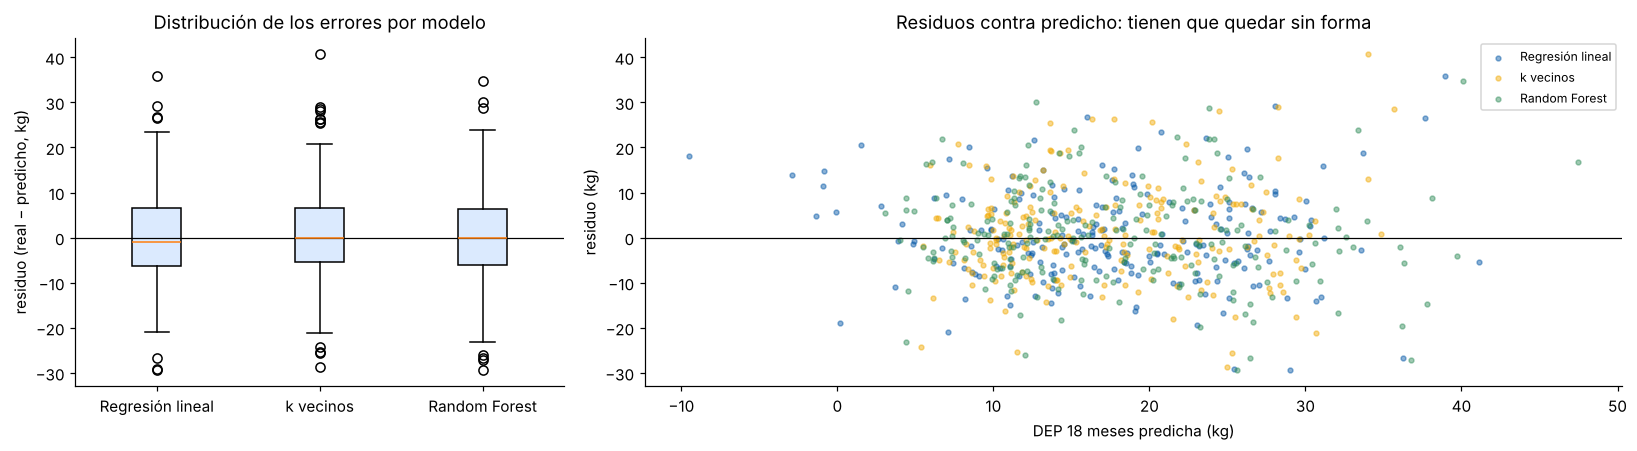

In [14]:
fig, (a, b) = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1, 2]})
res = {n: y_pru - resultados[n]["modelo"].predict(X_pru) for n in FINALES}
a.boxplot([res[n] for n in FINALES], tick_labels=FINALES, patch_artist=True,
          boxprops=dict(facecolor="#dbeafe")); a.axhline(0, color="black", lw=0.8)
a.set_ylabel("residuo (real − predicho, kg)"); a.set_title("Distribución de los errores por modelo")
for n in FINALES:
    b.scatter(resultados[n]["modelo"].predict(X_pru), res[n], s=10, alpha=0.45, color=COLOR_MODELO[n], label=n)
b.axhline(0, color="black", lw=0.8); b.set_xlabel("DEP 18 meses predicha (kg)"); b.set_ylabel("residuo (kg)"); b.legend(fontsize=8)
b.set_title("Residuos contra predicho: tienen que quedar sin forma")
plt.tight_layout(); fig.savefig(FIG / f"tp2_residuos_{RAZA}.png", bbox_inches="tight"); plt.show()

**Qué se ve.** Los errores de los tres modelos tienen cajas casi iguales y centradas en cero. Contra el predicho, los residuos no forman una curva (no hay una no linealidad evidente que la recta no capture), pero la dispersión es grande en todo el rango.

### C.3 · El mejor modelo
El criterio principal es el **RMSE de validación cruzada**, que usa los 884 toros de entrenamiento en cinco particiones y da la dispersión; la prueba confirma.

In [15]:
orden = sorted(FINALES, key=lambda n: resultados[n]["RMSE CV"][0])
MEJOR = orden[0]
print("Orden por RMSE de validación cruzada (criterio principal):")
for n in orden:
    print(f"  {n:18s} RMSE CV {resultados[n]['RMSE CV'][0]:.2f} ± {resultados[n]['RMSE CV'][1]:.2f} · RMSE prueba {resultados[n]['prueba']['RMSE']:.2f} · "
          f"MAE prueba {resultados[n]['prueba']['MAE']:.2f} · R² prueba {resultados[n]['prueba']['R²']:.3f}")
print(f"\nMejor modelo: {MEJOR}")
for m, menor in [("RMSE", True), ("MAE", True), ("R²", False)]:
    g = (min if menor else max)(FINALES, key=lambda n: resultados[n]["prueba"][m])
    print(f"  Si se prioriza {m} en prueba, gana: {g}")

Orden por RMSE de validación cruzada (criterio principal):
  Regresión lineal   RMSE CV 10.08 ± 0.30 · RMSE prueba 10.29 · MAE prueba 7.95 · R² prueba 0.379
  Random Forest      RMSE CV 10.33 ± 0.38 · RMSE prueba 10.58 · MAE prueba 8.04 · R² prueba 0.343
  k vecinos          RMSE CV 10.48 ± 0.35 · RMSE prueba 10.49 · MAE prueba 7.84 · R² prueba 0.354

Mejor modelo: Regresión lineal
  Si se prioriza RMSE en prueba, gana: Regresión lineal
  Si se prioriza MAE en prueba, gana: k vecinos
  Si se prioriza R² en prueba, gana: Regresión lineal


**La elección:** **regresión lineal múltiple.** Tiene el menor RMSE en validación cruzada (10,08 ± 0,30 kg) y en prueba (10,29 kg), el mayor R² (0,379 en prueba, 0,402 en validación cruzada), la menor brecha entre entrenamiento y prueba, y es el más simple e interpretable. La ventaja sobre Random Forest (10,33 ± 0,38) y k vecinos (10,48 ± 0,35) es de 0,25 a 0,40 kg, del orden de un desvío de la validación cruzada: es un **empate técnico** que se resuelve a favor del modelo más simple. Si se priorizara el MAE, k vecinos queda primero por 0,11 kg (7,84 contra 7,95 kg), una diferencia sin peso práctico.

### C.4 · Análisis de residuos del mejor modelo (extensión)
Distribución, gráfico Q-Q, residuos contra predicho, test de normalidad (Shapiro-Wilk y D'Agostino-Pearson) y test de homocedasticidad de Breusch-Pagan (implementado a mano: se regresa el residuo al cuadrado sobre las predictoras y LM = n·R² sigue una χ² con tantos grados de libertad como predictoras).

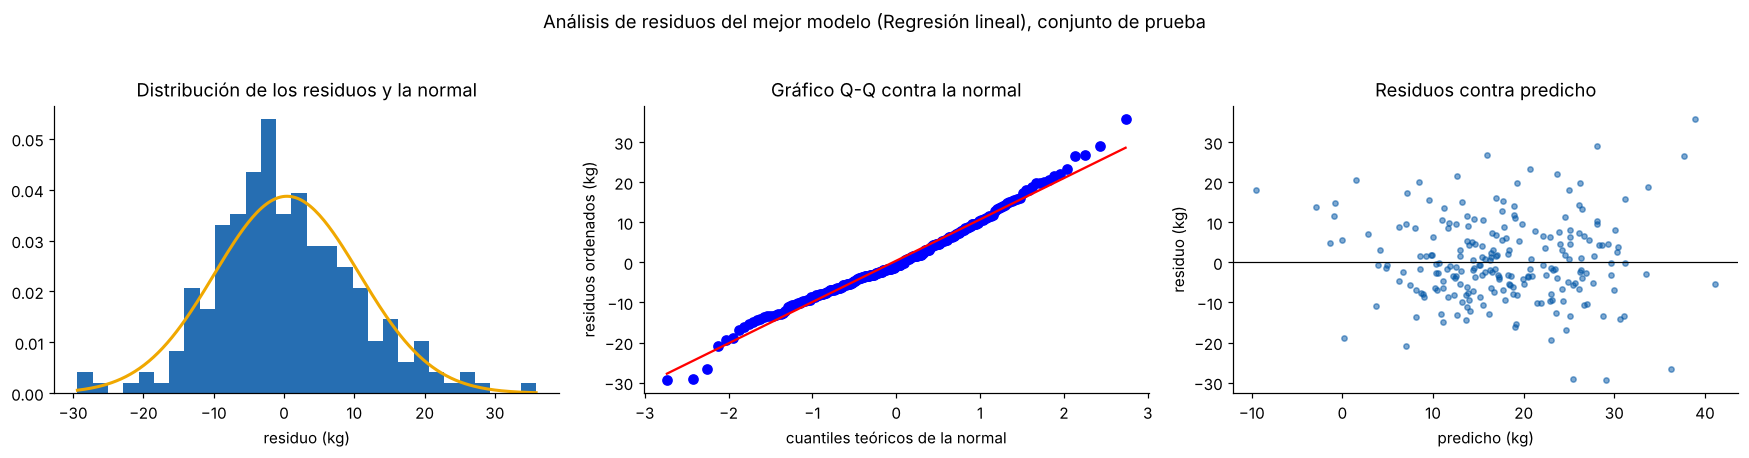

Media de los residuos: 0.42 kg · desvío 10.30 kg · asimetría 0.30 · curtosis 0.69
Shapiro-Wilk: W = 0.986, p = 0.0317
D'Agostino-Pearson: K² = 7.12, p = 0.0284
Breusch-Pagan (homocedasticidad): LM = 13.46, p = 0.0194


In [16]:
mod = resultados[MEJOR]["modelo"]; pred = mod.predict(X_pru); e = y_pru - pred
fig, ejes = plt.subplots(1, 3, figsize=(16, 4))
ejes[0].hist(e, bins=30, color=AZUL, alpha=0.85, density=True)
xs = np.linspace(e.min(), e.max(), 200); ejes[0].plot(xs, stats.norm.pdf(xs, e.mean(), e.std()), color=AMBAR, lw=2)
ejes[0].set_title("Distribución de los residuos y la normal"); ejes[0].set_xlabel("residuo (kg)")
stats.probplot(e, dist="norm", plot=ejes[1]); ejes[1].set_title("Gráfico Q-Q contra la normal")
ejes[1].set_xlabel("cuantiles teóricos de la normal"); ejes[1].set_ylabel("residuos ordenados (kg)")
ejes[2].scatter(pred, e, s=12, alpha=0.5, color=AZUL); ejes[2].axhline(0, color="black", lw=0.8)
ejes[2].set_xlabel("predicho (kg)"); ejes[2].set_ylabel("residuo (kg)"); ejes[2].set_title("Residuos contra predicho")
fig.suptitle(f"Análisis de residuos del mejor modelo ({MEJOR}), conjunto de prueba", y=1.03)
plt.tight_layout(); fig.savefig(FIG / f"tp2_residuos_mejor_{RAZA}.png", bbox_inches="tight"); plt.show()

sh = stats.shapiro(e); da = stats.normaltest(e)
# Breusch-Pagan, a mano: se regresan los residuos al cuadrado sobre las predictoras; LM = n · R²
Z = mod[:-1].transform(X_pru); e2 = e.to_numpy() ** 2
aux = LinearRegression().fit(Z, e2); lm = len(e2) * aux.score(Z, e2); p_bp = stats.chi2.sf(lm, df=Z.shape[1])
print(f"Media de los residuos: {e.mean():.2f} kg · desvío {e.std():.2f} kg · asimetría {stats.skew(e):.2f} · curtosis {stats.kurtosis(e):.2f}")
print(f"Shapiro-Wilk: W = {sh.statistic:.3f}, p = {sh.pvalue:.4f}")
print(f"D'Agostino-Pearson: K² = {da.statistic:.2f}, p = {da.pvalue:.4f}")
print(f"Breusch-Pagan (homocedasticidad): LM = {lm:.2f}, p = {p_bp:.4f}")

**Lectura.** Los residuos están centrados (media 0,4 kg) y son casi simétricos, con una cola algo más pesada a la derecha (asimetría 0,30): los toros excepcionales quedan por encima de lo que el modelo predice. Los tests rechazan la normalidad estricta y la homocedasticidad al 5 % (p = 0,03 y p = 0,02), pero por poco: el Q-Q sigue la recta salvo en los extremos. Para predecir no es grave; para construir intervalos de confianza clásicos habría que tenerlo en cuenta.

### C.5 · Curvas de aprendizaje (extensión)

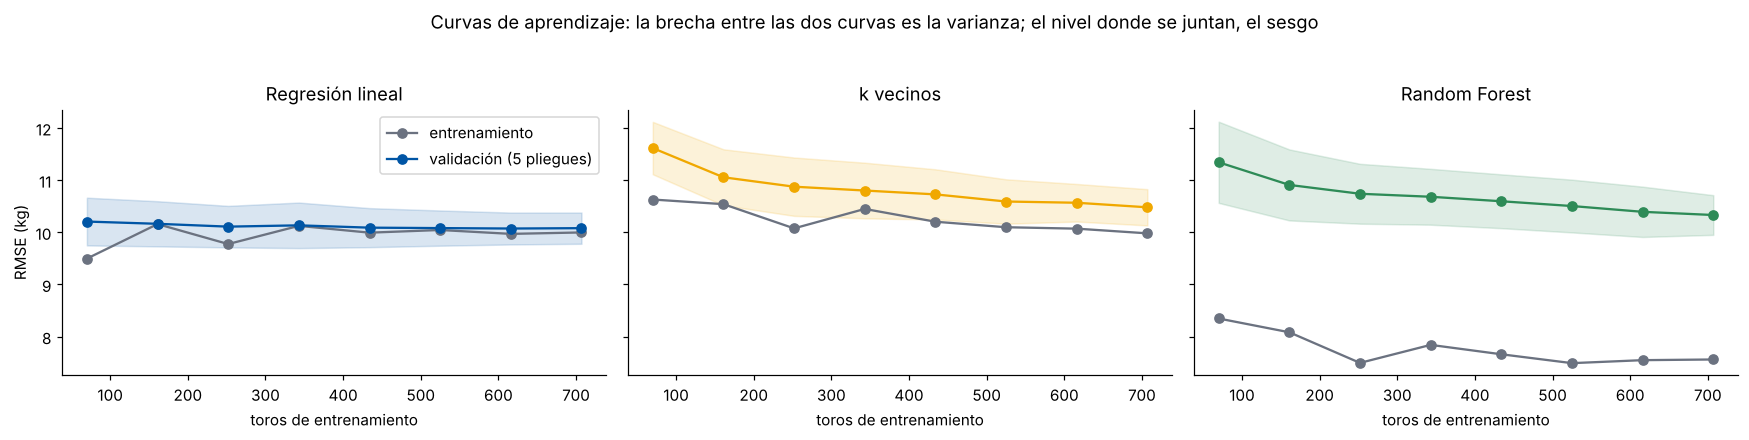

In [17]:
fig, ejes = plt.subplots(1, 3, figsize=(16, 3.8), sharey=True)
for ax, n in zip(ejes, FINALES):
    tam, te, tv = learning_curve(resultados[n]["modelo"], X_ent, y_ent, cv=pliegues, train_sizes=np.linspace(0.1, 1.0, 8),
                                 scoring="neg_root_mean_squared_error", n_jobs=-1)
    ax.plot(tam, -te.mean(1), marker="o", color=GRIS, label="entrenamiento")
    ax.plot(tam, -tv.mean(1), marker="o", color=COLOR_MODELO[n], label="validación (5 pliegues)")
    ax.fill_between(tam, -tv.mean(1) - tv.std(1), -tv.mean(1) + tv.std(1), color=COLOR_MODELO[n], alpha=0.15)
    ax.set_title(n); ax.set_xlabel("toros de entrenamiento")
ejes[0].set_ylabel("RMSE (kg)"); ejes[0].legend()
fig.suptitle("Curvas de aprendizaje: la brecha entre las dos curvas es la varianza; el nivel donde se juntan, el sesgo", y=1.04)
plt.tight_layout(); fig.savefig(FIG / f"tp2_curvas_{RAZA}.png", bbox_inches="tight"); plt.show()

**Qué se ve.** En la regresión lineal las dos curvas se juntan enseguida cerca de 10 kg: con unos cientos de toros ya no mejora, y **más datos no van a bajar el error; harían falta otras variables**. En k vecinos y Random Forest queda una brecha (varianza) y la curva de validación todavía baja despacio: con muchos más toros podrían acercarse a la recta, pero no hay indicio de que la superen.

### C.6 · Importancia de las variables (extensión)
Importancia por permutación sobre la prueba (cuánto empeora el RMSE si se mezcla una columna) para los tres modelos, y los coeficientes escalados de la regresión lineal.

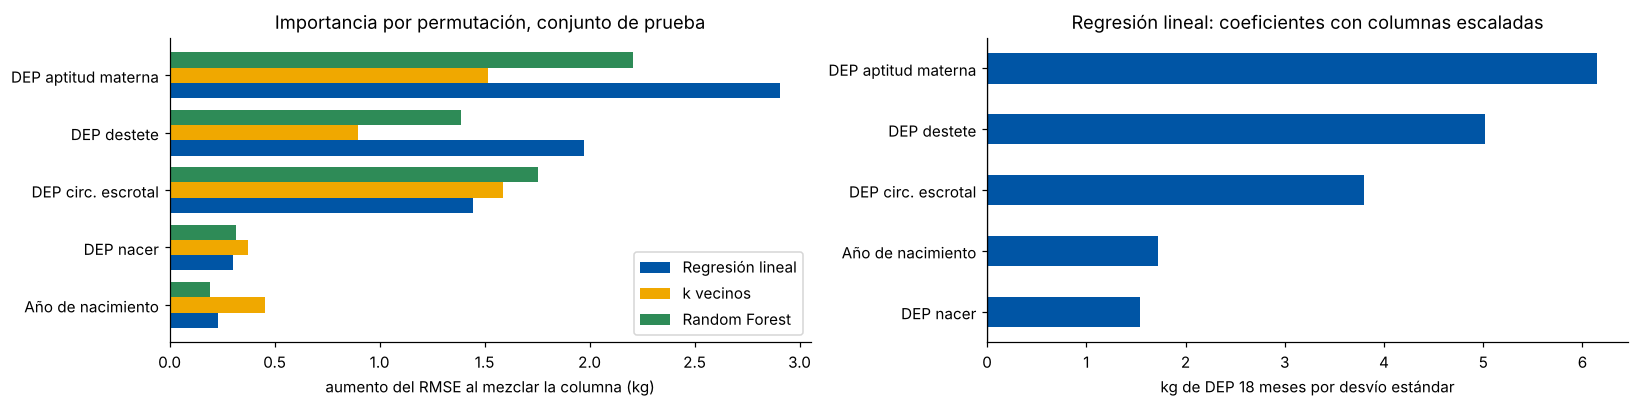

,Regresión lineal,k vecinos,Random Forest
DEP nacer,0.30,0.38,0.31
DEP destete,1.97,0.90,1.39
DEP aptitud materna,2.91,1.52,2.21
DEP circ. escrotal,1.44,1.59,1.75
Año de nacimiento,0.23,0.46,0.19


In [18]:
imp = {}
for n in FINALES:
    r = permutation_importance(resultados[n]["modelo"], X_pru, y_pru, scoring="neg_root_mean_squared_error", n_repeats=20, random_state=SEMILLA)
    imp[n] = pd.Series(r.importances_mean, index=[NOMBRES[c] for c in PREDICTORAS])
imp = pd.DataFrame(imp)
fig, (a, b) = plt.subplots(1, 2, figsize=(15, 3.8))
imp.sort_values(MEJOR).plot.barh(ax=a, color=[COLOR_MODELO[n] for n in FINALES], width=0.8)
a.set_xlabel("aumento del RMSE al mezclar la columna (kg)"); a.set_title("Importancia por permutación, conjunto de prueba")
coef.sort_values().plot.barh(ax=b, color=[AZUL if v >= 0 else ROJO for v in coef.sort_values()])
b.axvline(0, color="black", lw=0.8); b.set_xlabel("kg de DEP 18 meses por desvío estándar"); b.set_title("Regresión lineal: coeficientes con columnas escaladas")
plt.tight_layout(); fig.savefig(FIG / f"tp2_importancia_{RAZA}.png", bbox_inches="tight"); plt.show()
imp.round(2)

**Qué se ve.** Los tres modelos coinciden en lo principal: **aptitud materna, destete y circunferencia escrotal** explican casi toda la predicción; el peso al nacer y el año aportan poco. Que tres algoritmos tan distintos lleguen al mismo orden da solidez a la conclusión.

## 6 · Réplica en Brangus
Los mismos tres algoritmos, la misma partición y las mismas grillas de hiperparámetros, sobre los 1223 toros Brangus.

In [19]:
def correr_raza(raza):
    d = toros[toros["Raza"] == raza].reset_index(drop=True)
    Xe, Xp, ye, yp = train_test_split(d[PREDICTORAS], d[OBJETIVO], test_size=0.2, random_state=SEMILLA)
    modelos = {"Regresión lineal": flujo(LinearRegression()),
               "k vecinos": GridSearchCV(flujo(KNeighborsRegressor()), grilla_knn, cv=pliegues, scoring="neg_root_mean_squared_error"),
               "Random Forest": GridSearchCV(flujo(RandomForestRegressor(n_estimators=300, random_state=SEMILLA, n_jobs=-1), escalar=False),
                                             grilla_rf, cv=pliegues, scoring="neg_root_mean_squared_error", n_jobs=-1)}
    filas = {}
    for n, m in modelos.items():
        m.fit(Xe, ye); fin = m.best_estimator_ if hasattr(m, "best_estimator_") else m
        cv = cross_validate(fin, Xe, ye, cv=pliegues, scoring=("neg_root_mean_squared_error", "r2"))
        me, mp = metricas(ye, fin.predict(Xe)), metricas(yp, fin.predict(Xp))
        filas[n] = {"RMSE ent.": me["RMSE"], "RMSE prueba": mp["RMSE"], "MAE prueba": mp["MAE"], "R² ent.": me["R²"], "R² prueba": mp["R²"],
                    "R² ajust. prueba": mp["R² ajustado"], "RMSE CV": -cv["test_neg_root_mean_squared_error"].mean(),
                    "RMSE CV desvío": cv["test_neg_root_mean_squared_error"].std(), "R² CV": cv["test_r2"].mean(),
                    "hiperparámetros": getattr(m, "best_params_", "por defecto")}
    return pd.DataFrame(filas).T, d

tabla_bg, datos_bg = correr_raza("Brangus")
print(f"Brangus: {len(datos_bg)} toros · DEP 18 meses media {datos_bg[OBJETIVO].mean():.1f} kg, desvío {datos_bg[OBJETIVO].std():.1f} kg")
tabla_bg

Brangus: 1223 toros · DEP 18 meses media 18.8 kg, desvío 9.6 kg


,RMSE ent.,RMSE prueba,MAE prueba,R² ent.,R² prueba,R² ajust. prueba,RMSE CV,RMSE CV desvío,R² CV,hiperparámetros
Regresión lineal,5.407209,5.278091,3.949109,0.690234,0.660234,0.653126,5.438547,0.458415,0.681399,por defecto
k vecinos,5.53228,5.892916,4.455841,0.675738,0.576468,0.567608,6.113992,0.612734,0.600169,"{'modelo__n_neighbors': 10, 'modelo__weights':..."
Random Forest,4.780231,5.524865,4.033447,0.757905,0.627721,0.619932,5.804463,0.460834,0.637899,"{'modelo__max_depth': None, 'modelo__max_featu..."


**Qué se ve.** El orden de los modelos se repite (regresión lineal primero, Random Forest segundo, k vecinos tercero), pero con un nivel mucho más alto: la regresión lineal explica el 66 % de la variación en prueba (68 % en validación cruzada), con un RMSE de 5,3 kg. En Brangus las DEP tempranas anticipan mucho mejor la de 18 meses; es la misma diferencia entre razas que mostró el TP1.

In [20]:
salida = {"raza": RAZA, "n": len(datos), "n_ent": len(X_ent), "n_pru": len(X_pru), "mejor": MEJOR,
          "objetivo_media": float(y.mean()), "objetivo_desvio": float(y.std()),
          "modelos": {n: {"entrenamiento": resultados[n]["entrenamiento"], "prueba": resultados[n]["prueba"],
                          "RMSE CV": resultados[n]["RMSE CV"], "R² CV": resultados[n]["R² CV"]} for n in resultados},
          "hiper_knn": busq_knn.best_params_, "hiper_rf": {k: (None if v is None else v) for k, v in busq_rf.best_params_.items()},
          "coef_lineal": coef.to_dict(), "intercepto": float(lineal["modelo"].intercept_),
          "importancia": imp.to_dict(), "residuos": {"shapiro_p": float(sh.pvalue), "dagostino_p": float(da.pvalue), "bp_lm": float(lm), "bp_p": float(p_bp),
                                                     "media": float(e.mean()), "desvio": float(e.std()), "asimetria": float(stats.skew(e)), "curtosis": float(stats.kurtosis(e))},
          "brangus": json.loads(tabla_bg.drop(columns="hiperparámetros").to_json(orient="index")),
          "brangus_hiper": {k: str(v) for k, v in tabla_bg["hiperparámetros"].items()}}
Path("resultados_tp2.json").write_text(json.dumps(salida, ensure_ascii=False, indent=1, default=float))
print("Guardado: resultados_tp2.json y las figuras en figuras/")

Guardado: resultados_tp2.json y las figuras en figuras/


## 8 · Cuestionario de interpretación

**1. ¿Cuál fue el modelo más adecuado y cambiaría la elección con otra métrica?**
La **regresión lineal múltiple**: menor RMSE en validación cruzada (10,08 ± 0,30 kg) y en prueba (10,29 kg), mayor R² en prueba (0,379) y en validación cruzada (0,402), y la menor diferencia entre entrenamiento y prueba. Con RMSE y R² la elección no cambia. Con MAE gana k vecinos por 0,11 kg (7,84 contra 7,95 kg): el MAE pesa igual todos los errores y el RMSE castiga más los grandes; k vecinos comete algunos errores grandes más (su RMSE es mayor) pero un poco menos de errores medianos. La diferencia es menor que la dispersión entre pliegues, así que no cambia la decisión. En Brangus la regresión lineal gana con las tres métricas.

**2. ¿Hubo sobreajuste o subajuste? ¿Cómo se detectó?**
- **Random Forest con valores por defecto sobreajusta fuerte:** R² 0,914 en entrenamiento contra 0,336 en prueba. Es **varianza**: árboles sin límite memorizan a cada toro. Se mitigó limitando la profundidad (8) y exigiendo 5 toros por hoja (R² 0,664 contra 0,343); también ayudarían menos columnas por árbol o más datos.
- **k vecinos con k = 5 sobreajusta** (0,547 contra 0,287); con k = 20, elegido por validación cruzada, la brecha casi desaparece. Subir k cambia varianza por sesgo.
- **La regresión lineal no sobreajusta** (0,415 contra 0,379), pero tiene **sesgo**: el error es alto en entrenamiento y en prueba, y la curva de aprendizaje se aplana en 10 kg con unos cientos de toros. Más datos no la mejoran.
- Se detectó comparando métricas de entrenamiento y prueba, con las curvas de aprendizaje y con la validación cruzada.

**3. ¿Qué características del problema explican el desempeño? ¿Quedan patrones sin capturar?**
- **La relación es casi aditiva.** La DEP de 18 meses se comporta como una suma ponderada de las DEP tempranas; los modelos flexibles no encuentran no linealidades que aprovechar y pagan su flexibilidad con varianza. Con 884 toros y 5 predictoras, el modelo con menos parámetros es el que mejor generaliza.
- **Las DEP salen de un modelo genético lineal** (BLUP), que las calcula como combinaciones de información de parientes y caracteres correlacionados: es esperable que su relación sea lineal.
- **La raza importa:** en Braford el destete se relaciona poco con los 18 meses (correlación 0,22) y el R² queda en 0,38; en Brangus llega a 0,66.
- **Patrones sin capturar:** los residuos del mejor modelo no muestran curvatura, pero tienen cola a la derecha (los toros excepcionales quedan subestimados) y una heterocedasticidad leve. Lo que falta no es forma del modelo sino **información**: el crecimiento posdestete propio de cada toro, que solo aparece cuando se pesan sus hijos a los 18 meses.

## 9 · Conclusión
Para estimar la DEP de 18 meses de un toro Braford a partir de sus caracteres tempranos alcanza una **regresión lineal múltiple**: explica cerca del 40 % de la variación con un error típico de 10 kg, no sobreajusta y se interpreta directamente (aptitud materna, destete y circunferencia escrotal son lo que más pesa). Los modelos más complejos no la superan. En Brangus el mismo modelo explica dos tercios de la variación. Sirve para ordenar toros jóvenes, no para reemplazar la DEP de 18 meses cuando tenga precisión.